# Task 6 (Level 3 — Advanced): Support Vector Machine (Linear vs RBF) & Decision Boundary Geometry

Compares Linear and Radial Basis Function (RBF) SVMs scaled strictly inside a scikit-learn `Pipeline` on binary Customer Churn classification, and visualises 2D decision boundaries alongside high-dimensional PCA projection limitations.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
m6 = json.loads((ROOT / 'results/metrics/task6_svm_metrics.json').read_text())
kern_df = pd.read_csv(ROOT / 'results/tables/task6_svm_kernel_comparison.csv')
comp_df = pd.read_csv(ROOT / 'reports/model_comparison.csv')
print('Selected Kernel:', m6['selected_kernel'].upper(), '| Support Vectors:', m6['rbf_svm']['n_support_vectors_total'])
print('2D PCA Explained Variance Ratio (PC1+PC2):', m6['pca_2d_explained_variance_total'])
display(kern_df)
print('\nComplete Portfolio Model Comparison Table:')
display(comp_df)

Selected Kernel: RBF | Support Vectors: 1389
2D PCA Explained Variance Ratio (PC1+PC2): 0.177954


,kernel,best_C,best_gamma,class_weight,cv_roc_auc,oof_threshold,test_roc_auc,test_pr_auc,test_accuracy,test_precision,test_recall,test_f1
0,linear,0.1,NaN,balanced,0.810470,0.24,0.825819,0.424558,0.824588,0.415385,0.568421,0.48000
1,rbf,1.0,scale,balanced,0.891303,0.32,0.913029,0.728359,0.910045,0.669903,0.726316,0.69697



Complete Portfolio Model Comparison Table:


,task_id,level,dataset,model_name,selection_procedure,threshold_or_k,cv_primary_metric,accuracy,precision,recall,f1_primary,f1_macro,roc_auc,pr_auc
0,Task 2 / Task 4 Baseline,Level 1–2,"Iris (test n=30, stratified 80/20)",DummyClassifier (Stratified),Baseline reference,NaN,NaN,0.5000,0.4897,0.5000,0.4894,0.4894,0.6250,NaN
1,Task 2,Level 1 (Basic),"Iris (test n=30, stratified 80/20)",KNN Unscaled (K=3),Ablation (raw cm units),K=3,NaN,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,NaN
2,Task 2,Level 1 (Basic),"Iris (test n=30, stratified 80/20)","KNN Scaled (K=3, uniform)",5-Fold Stratified CV on Train (n=120),K=3,0.9665,0.9333,0.9444,0.9333,0.9327,0.9327,0.9933,NaN
3,Task 4,Level 2 (Intermediate),"Iris (test n=30, stratified 80/20)","Decision Tree Unrestricted (Depth=5, Leaves=8)",Unpruned baseline (ccp_alpha=0.0),alpha=0.0,0.9496,0.9333,0.9333,0.9333,0.9333,0.9333,0.9500,NaN
4,Task 4,Level 2 (Intermediate),"Iris (test n=30, stratified 80/20)","Decision Tree Pruned (Depth=3, Leaves=4)",5-Fold Stratified CV + Parsimony Pruning on Tr...,alpha=0.008114,0.9663,0.9667,0.9697,0.9667,0.9666,0.9666,0.9817,NaN
5,Task 3 / 5 / 6 Baseline,Level 2–3,Customer Churn (churn-bigml-20),DummyClassifier (Most Frequent),Majority-class baseline,0.50,0.5000,0.8576,0.0000,0.0000,0.0000,0.4617,0.5000,0.1424
6,Task 3,Level 2 (Intermediate),Customer Churn (churn-bigml-20),Logistic Regression (Default Thr=0.50),5-Fold Stratified CV on churn-bigml-80,0.50,0.8112,0.7661,0.3512,0.7579,0.4800,0.6646,0.8274,0.4271
7,Task 3,Level 2 (Intermediate),Customer Churn (churn-bigml-20),Logistic Regression (OOF-Calibrated),5-Fold Stratified CV + OOF Threshold on churn-...,0.64,0.8112,0.8246,0.4113,0.5368,0.4658,0.6804,0.8274,0.4271
8,Task 6,Level 3 (Advanced),Customer Churn (churn-bigml-20),"SVM (Linear Kernel, OOF-Calibrated)",5-Fold Stratified CV + OOF Threshold on churn-...,0.24,0.8105,0.8246,0.4154,0.5684,0.4800,0.6872,0.8258,0.4246
9,Task 6,Level 3 (Advanced),Customer Churn (churn-bigml-20),"SVM (RBF Kernel, OOF-Calibrated)",5-Fold Stratified CV + OOF Threshold on churn-...,0.32,0.8913,0.9100,0.6699,0.7263,0.6970,0.8221,0.9130,0.7284


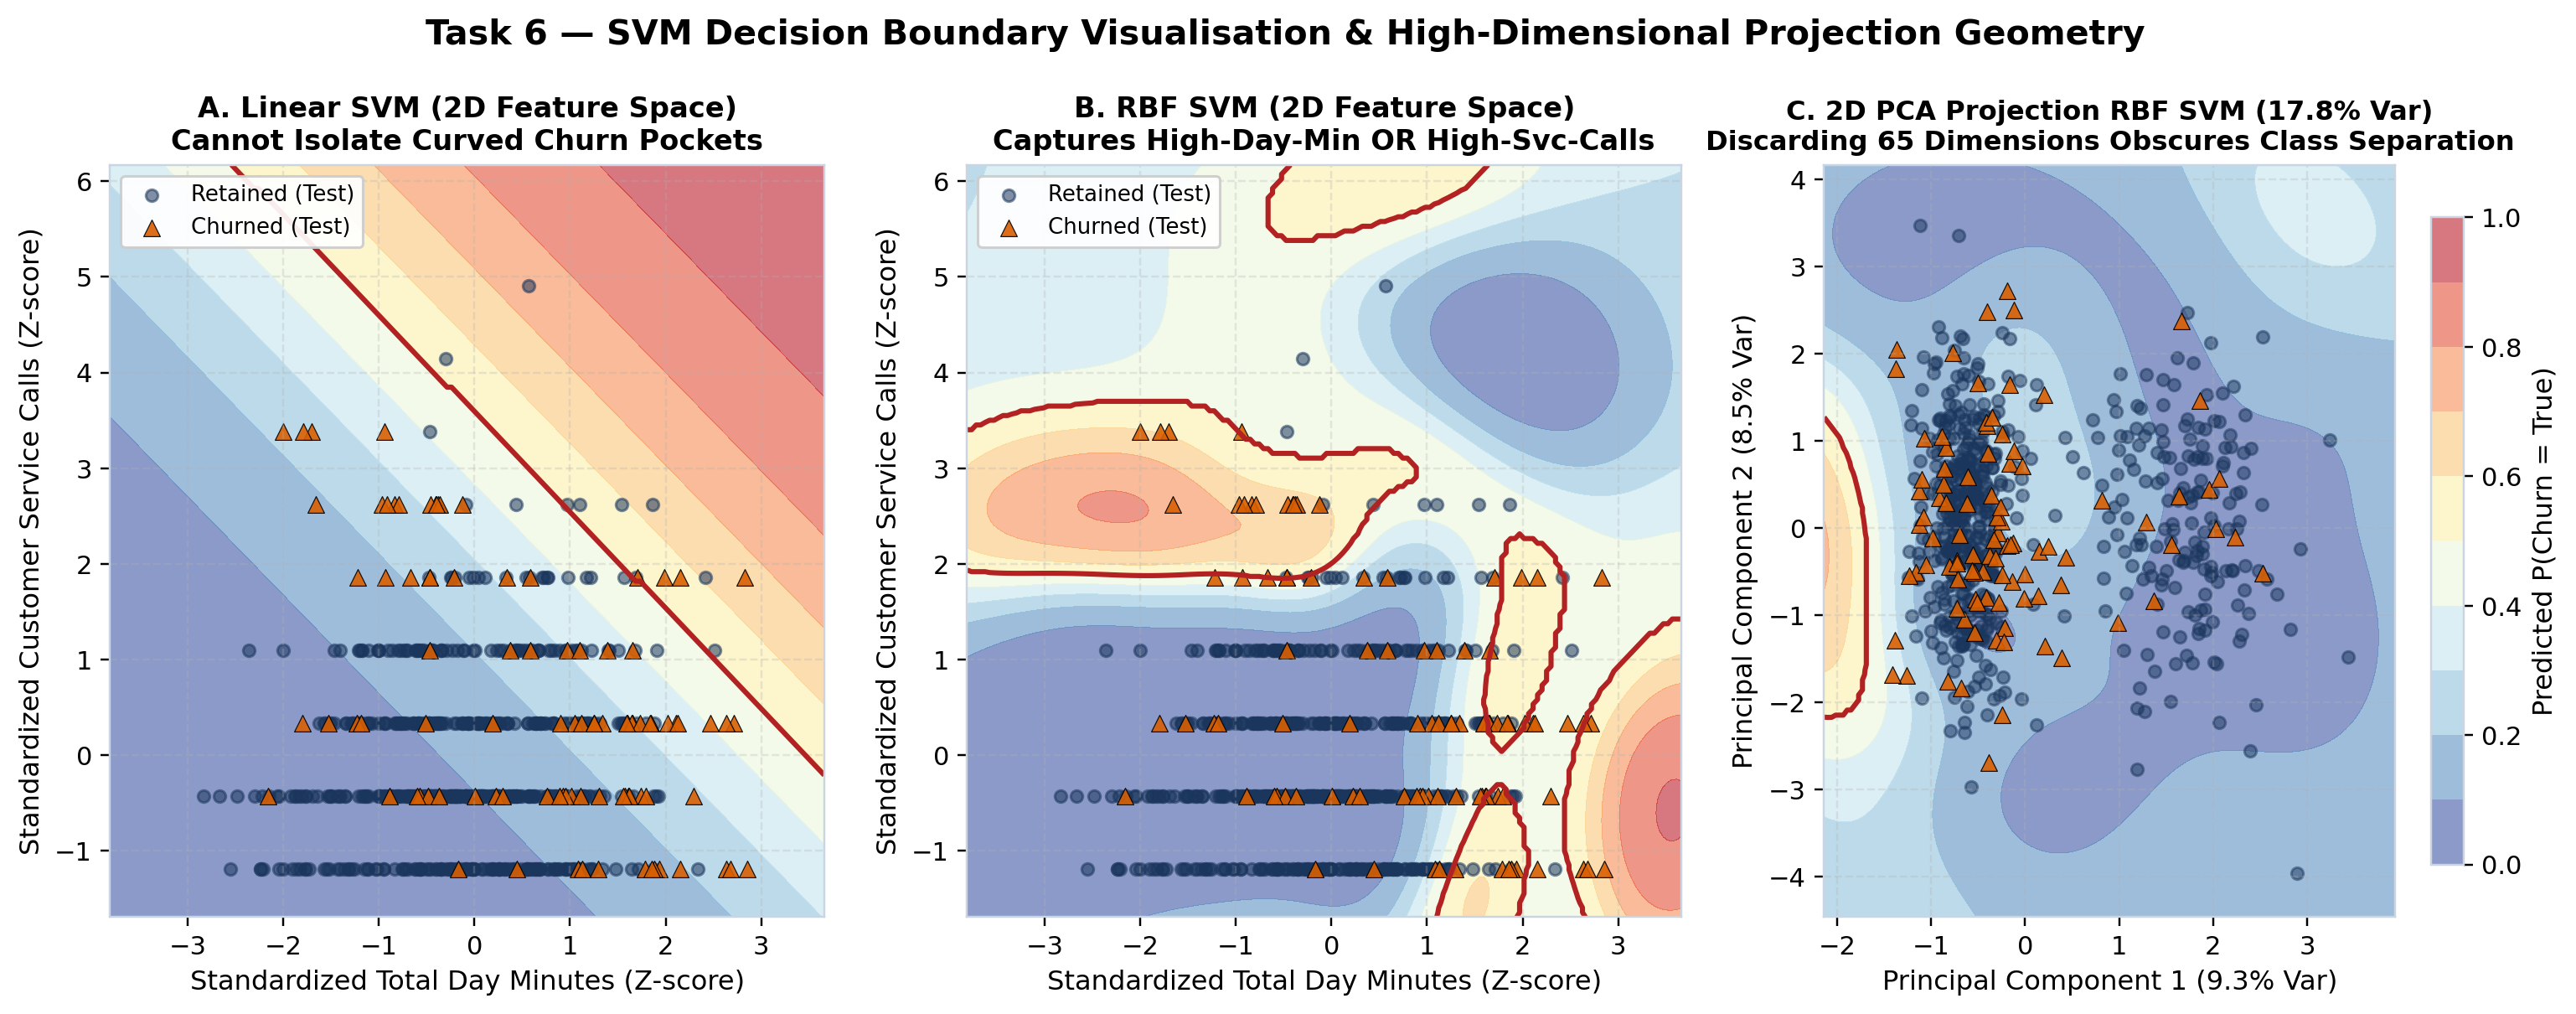

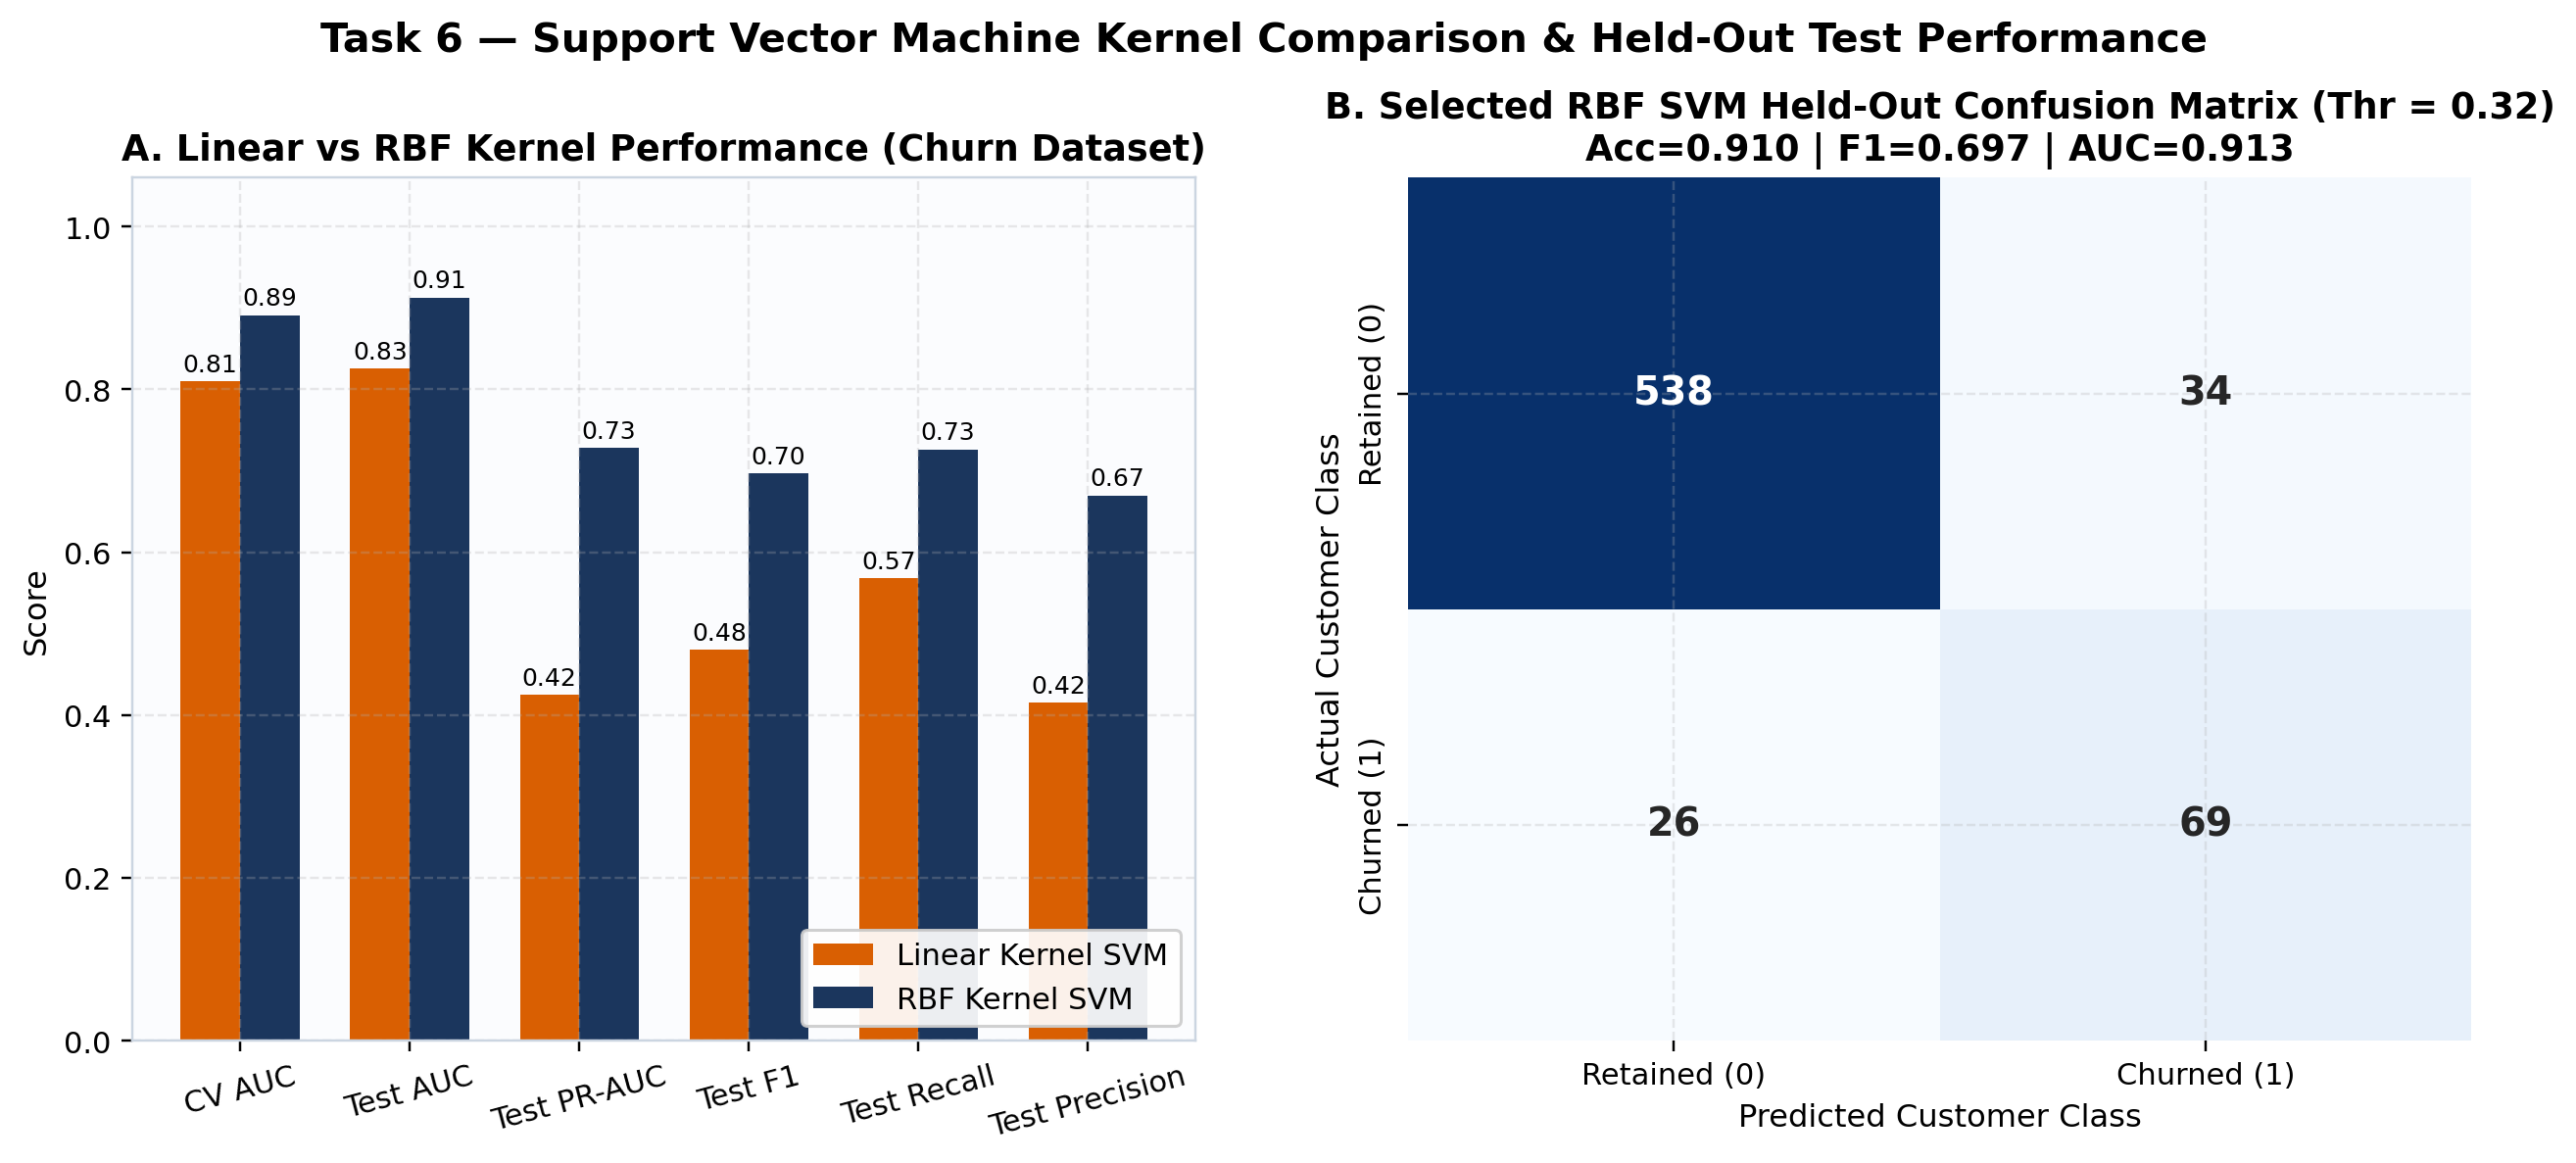

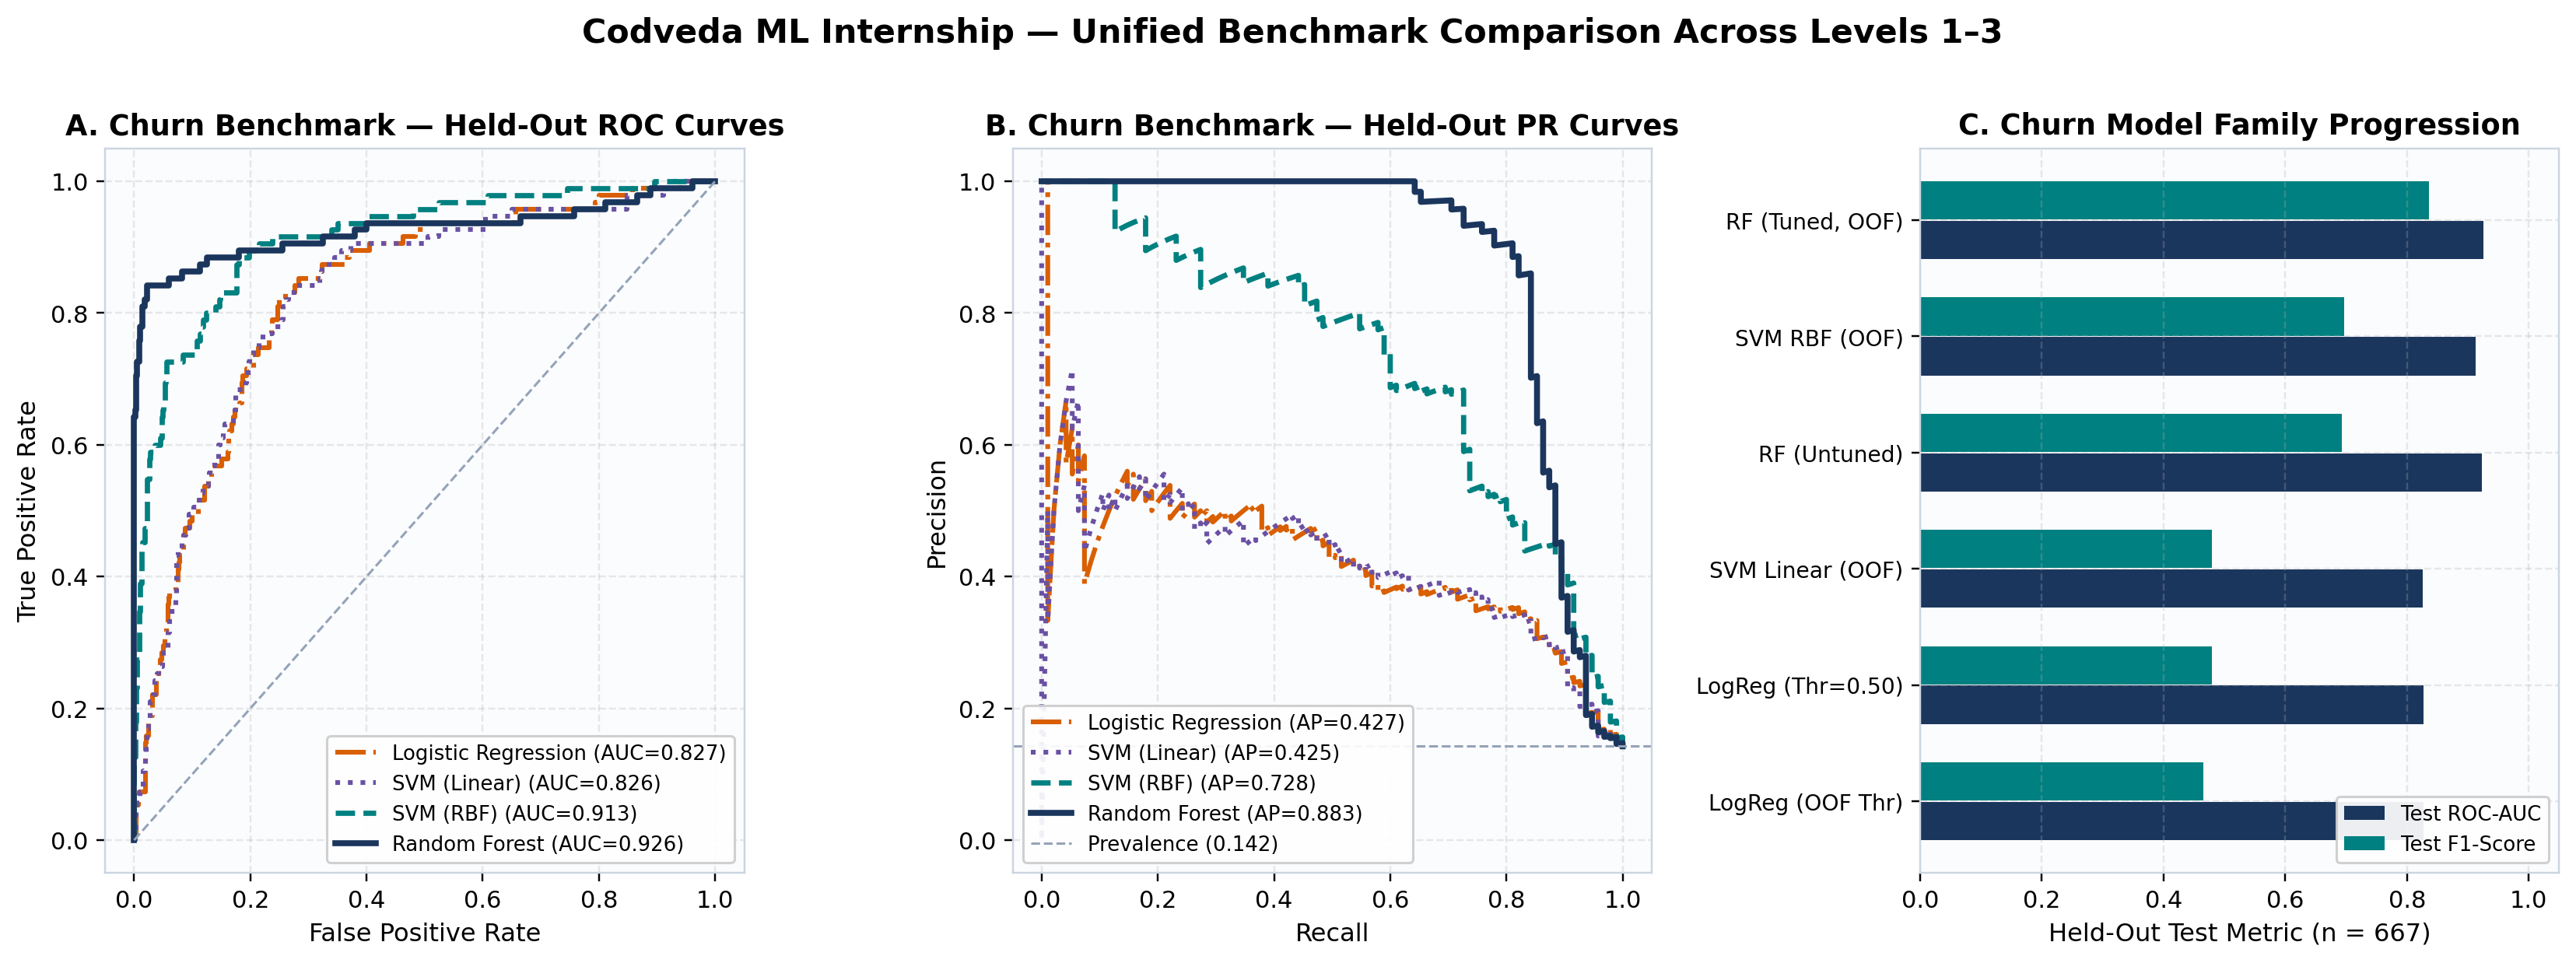

In [2]:
display(Image(filename=str(ROOT / 'results/figures/fig14_svm_decision_boundaries_2d.png')))
display(Image(filename=str(ROOT / 'results/figures/fig15_svm_kernel_comparison_and_confusion.png')))
display(Image(filename=str(ROOT / 'results/figures/fig16_portfolio_model_comparison_summary.png')))